# Machine Learning Engineering

CSI 4106 - Fall 2026

Marcel Turcotte  
Version: Oct 13, 2026 11:54

# Preamble

## Message of the Day

![](https://cohere-ai.ghost.io/content/images/size/w1600/2026/10/260902_OfficeAnnouncement_Ottawa_Blog.png)

<a
href="https://cohere.com/blog/cohere-expands-canadian-footprint-with-new-ottawa-office"
class="external" data-icon="true">Cohere Expands Canadian Footprint with
New Ottawa Office</a>, 2026-10-08.

>  **Aidan Gomez, Co-Founder and CEO**
>
> Canada is home for Cohere. It’s where we founded the company, where so
> much of our talent comes from, and where we want to keep building for
> the long term. Ottawa has an incredible technology community and a
> deep pool of technical talent. Establishing our first office in the
> city is an important step in investing in our team and building for
> the future.

We began the semester by introducing Joëlle Pineau and her role at
Cohere. Today, we return to Cohere as the company expands its presence
in Canada with a new permanent office in Ottawa. This is an exciting
development for our local AI community—and perhaps a future career
opportunity for some of you.

Two of Cohere’s co-founders have interesting connections to both Ottawa
and music.

[**Aidan Gomez**](https://aidangomez.ca/), Cohere’s co-founder and CEO,
was one of the eight authors of the landmark 2017 paper [*Attention Is
All You Need*](https://research.google/pubs/attention-is-all-you-need),
which introduced the Transformer architecture underlying modern large
language models. His path into machine learning also has a musical
connection. A pianist since childhood, he worked as an undergraduate on
an application that used neural networks to follow a live piano
performance and automatically turn the pages of the musical score.

[**Nick Frosst**](https://nickfrosst.com/), another Cohere co-founder,
grew up in Ottawa and says that he first learned to program at Bell High
School in Bells Corners. He later studied computer science and cognitive
science at the University of Toronto and became the first employee in
Geoffrey Hinton’s Google Brain lab in Toronto. Frosst also has a rather
unusual second career: he is the lead singer of the Canadian indie-rock
band [**Good Kid**](https://goodkidofficial.com/).

## Learning Objectives

- **Choose** an encoding that matches a feature’s meaning and the needs
  of the estimator.
- **Explain** when feature scaling matters and **apply** it without
  leaking validation or test information.
- **Compare** strategies for missing values and **implement** imputation
  within a pipeline.
- **Apply** class-imbalance remedies to training data without altering
  the evaluation distribution.
- **Construct** nonlinear and interaction features while controlling
  model complexity.
- **Explain** how data quality, coverage, and augmentation affect
  generalization.

# Machine Learning Engineering

## Machine Learning Engineering

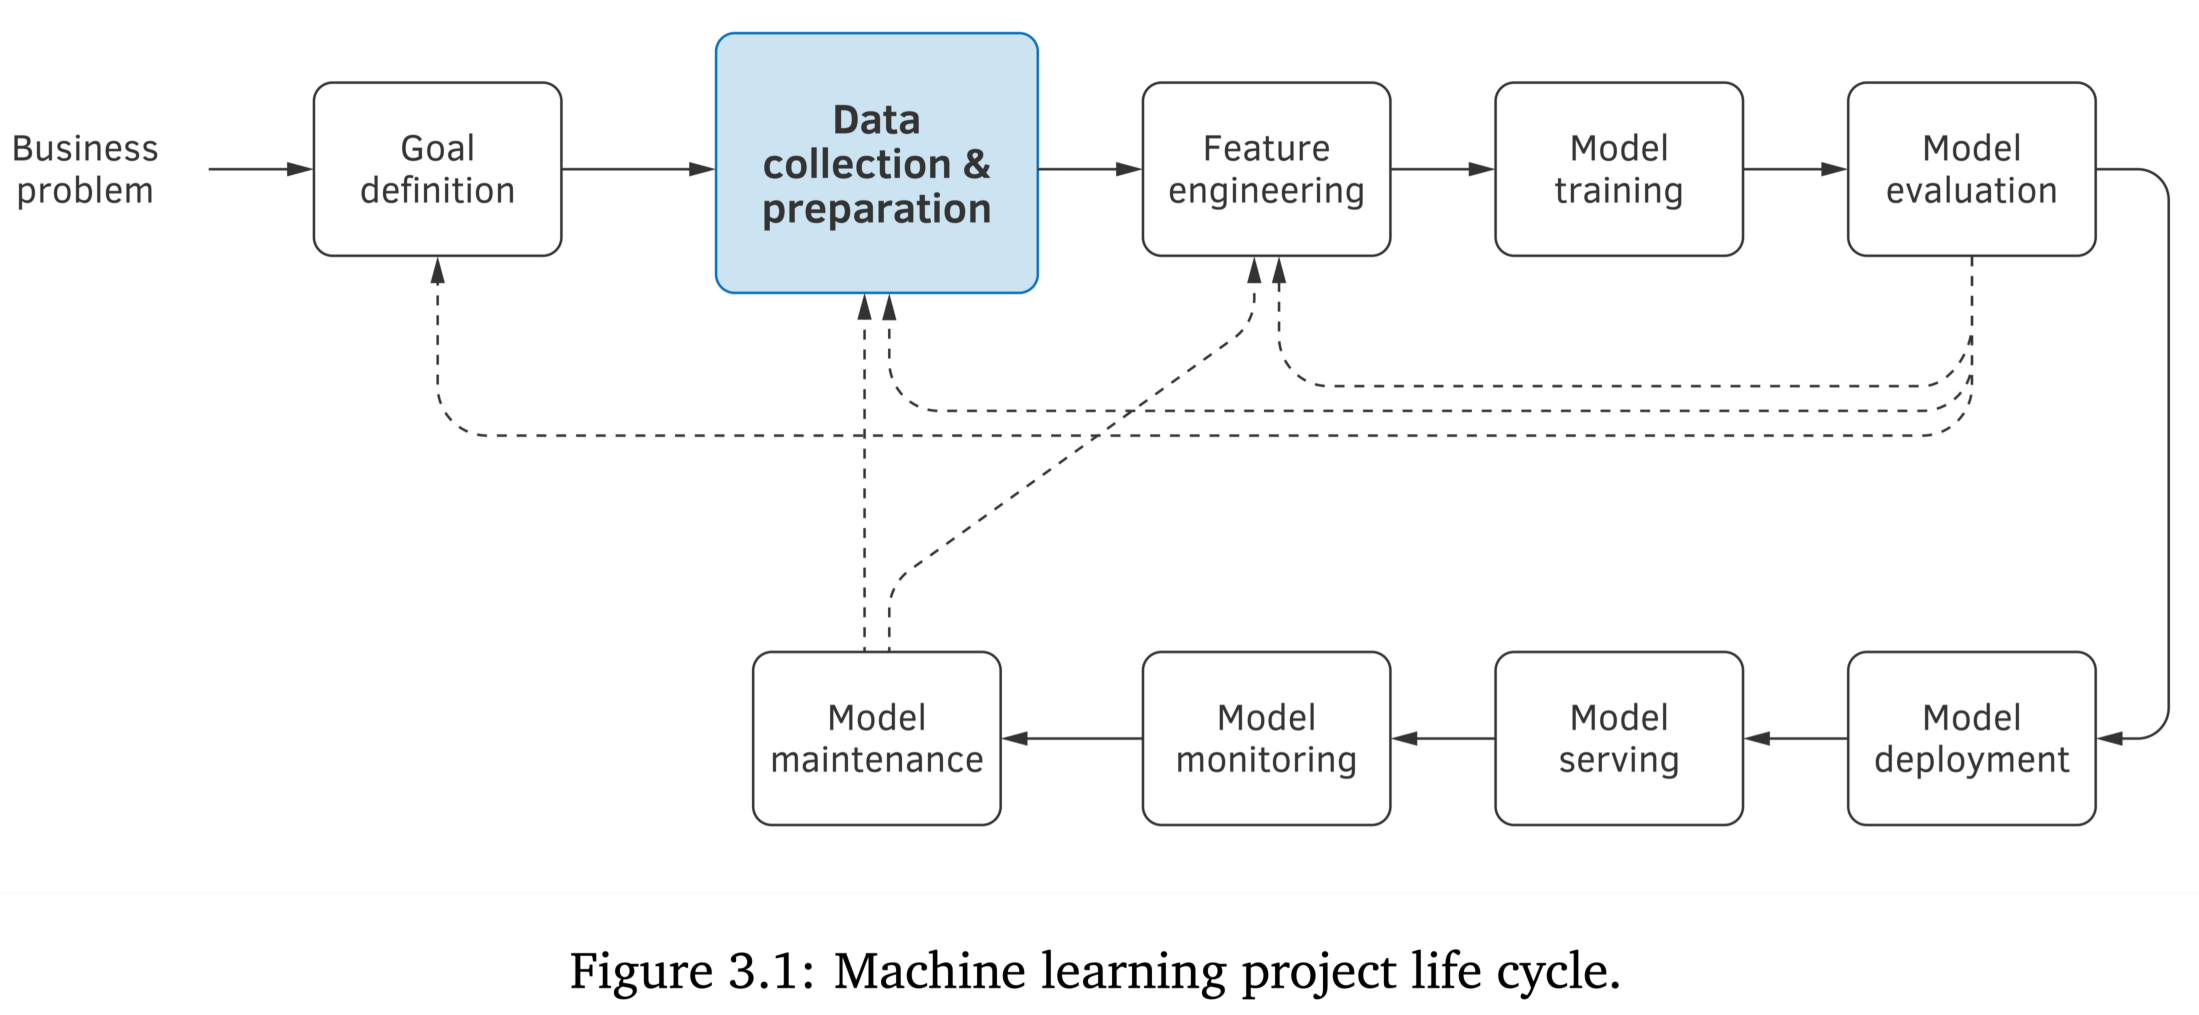

**Attribution:** Burkov (2020), Figure 3.1

The courses <a href="https://catalogue.uottawa.ca/search/?P=SDS%203386"
class="external" data-icon="true">SDS 3386: Data Science Lab</a> and
<a href="https://catalogue.uottawa.ca/search/?P=CSI%204142"
class="external" data-icon="true">CSI 4142: Fundamentals of Data
Science</a> provide comprehensive coverage of machine learning
engineering. This lecture introduces a focused subset of the
preprocessing and feature-engineering concepts used in those courses.

As illustrated, the life cycle of a machine learning project typically
involves multiple iterations. Each cycle enhances understanding of the
problem and reveals limitations. Insufficient data quality often
precipitates project failure.

### Characteristics of High-Quality Data

- **Volume**: Is the dataset sufficiently large to support
  generalization?
- **Relevance**: Do the features accurately model the problem?
- **Representation**: Does the data reflect the conditions expected in
  production?
  - Are these features obtainable from real-world inputs?
  - Does the dataset adequately cover and represent feature examples?
- **Bias**: Is the data free from bias?
- **Label Consistency**: Are the labels consistent throughout the
  dataset?

### Machine Learning Project Cycle

Gathering data and extracting features are the first two steps of a
machine learning project.

1.  Gather **adequate** data.
2.  Extract **features** from the raw data:
    - This process is **labor-intensive**.
    - It necessitates **creativity**.
    - **Domain knowledge** is highly beneficial.

# Encoding

## Why?

After completing Assignment 1, you generated a `.csv` file containing
cleaned data.

Why would additional steps be necessary?

## Dataset - Adult

In [2]:
import numpy as np
np.random.seed(42)

from sklearn.datasets import fetch_openml

adult = fetch_openml(name='adult', version=2)

print(adult.DESCR)

The ‘Adult’ dataset contains several attributes characterized by
categorical values. This dataset will serve as a basis for a brief
discussion on encoding these categorical values.

## Adult - Workclass

In [3]:
adult.data['workclass'].unique()

['Private', 'Local-gov', NaN, 'Self-emp-not-inc', 'Federal-gov', 'State-gov', 'Self-emp-inc', 'Without-pay', 'Never-worked']
Categories (8, str): ['Federal-gov', 'Local-gov', 'Never-worked', 'Private', 'Self-emp-inc', 'Self-emp-not-inc', 'State-gov', 'Without-pay']

## Adult - Education

In [4]:
adult.data['education'].unique()

['11th', 'HS-grad', 'Assoc-acdm', 'Some-college', '10th', ..., 'Assoc-voc', '9th', '12th', '1st-4th', 'Preschool']
Length: 16
Categories (16, str): ['10th', '11th', '12th', '1st-4th', ..., 'Masters', 'Preschool', 'Prof-school', 'Some-college']

## Adult - Marital Status

In [5]:
adult.data['marital-status'].unique()

['Never-married', 'Married-civ-spouse', 'Widowed', 'Divorced', 'Separated', 'Married-spouse-absent', 'Married-AF-spouse']
Categories (7, str): ['Divorced', 'Married-AF-spouse', 'Married-civ-spouse', 'Married-spouse-absent', 'Never-married', 'Separated', 'Widowed']

## Categorical Data

**Key Points on Data Representation**

- **Numerical Representation**: Many learning algorithms require
  numerical feature vectors.

- **Meaning Matters**: The representation should preserve whether
  categories are unordered or have an inherent order.

## Encoding Methods

Consider the `workclass` attribute, which has 8 distinct values like
‘Federal-gov’, ‘Local-gov’, and so on.

- **Which** encoding method is preferable and **why?**

1.  `w` = 1, 2, 3, 4, 5, 6, 7, or 8
2.  `w` = \[0,0,0\], \[0,0,1\], \[0,1,0\], $\ldots$, or \[1,1,1\]
3.  `w` = \[1,0,0,0,0,0,0,0\], \[0,1,0,0,0,0,0,0\], $\ldots$, or
    \[0,0,0,0,0,0,0,1\]

## Encoding Nominal Data

**One-hot encoding** is a common default for unordered, or **nominal**,
categories.

- **Increases Dimensionality**: One-hot encoding creates one output
  feature per retained category.
- **Avoids Artificial Order**: Integer codes can introduce distances and
  order that the categories do not possess.
- **Example of Bias**: Using the first method, `w` = 1, 2, 3, etc.,
  implies that ‘Federal-gov’ and ‘Local-gov’ are similar, while
  ‘Federal-gov’ and ‘Without-pay’ are not.
- **Misleading Similarity**: The second method, `w` = \[0,0,0\],
  \[0,0,1\], etc., might mislead the algorithm by suggesting similarity
  based on numeric patterns.

## Definition

**One-Hot Encoding**: A technique that converts categorical variables
into a binary vector representation, where each category is represented
by a vector with a single ‘1’ and all other elements as ‘0’.

High-cardinality attributes may require other representations, such as
grouping infrequent categories, hashing, target encoding, or learned
embeddings.

## OneHotEncoder

In [6]:
from sklearn.preprocessing import OneHotEncoder

work = adult.data[['workclass']]

onehot_encoder = OneHotEncoder(handle_unknown="ignore")

onehot_encoder.fit(work)
values_encoded = onehot_encoder.transform(work)

values_encoded[:5].toarray()

array([[0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1.]])

**Consistency is Key**: Ensure you use the same encoding on: Validation
Set, Test Set, and Production Data.

An encoder learns the categories and their column order during `fit`.
Fitting a second encoder on validation, test, or production data can
therefore change the meaning or number of columns. The correct pattern
is to fit the encoder on the training data and reuse its `transform`
method everywhere else. A pipeline applies this pattern automatically
during cross-validation.

While `Pandas` offers a method called `get_dummies()` for one-hot
encoding, it is important to note the following distinctions:

- **Category Memory**: `OneHotEncoder` retains the categories it was
  trained on, whereas `get_dummies()` does not.
- **Consistency in Production**: It is crucial to use the same encoding
  scheme in production as was used during training to ensure accurate
  results.
- **Vector Length Discrepancies**: If `get_dummies()` encounters a
  different number of categories in new data, it will produce vectors of
  varying lengths, leading to potential errors.
- **Handling Missing Values**: By default, `get_dummies()` encodes a
  missing value as all zeros. An explicit missing-value column is
  created only with `dummy_na=True`.

Ensuring consistency in encoding across **training**, **validation**,
and **production** datasets is essential to maintain the integrity and
accuracy of your machine learning models.

## Case Study

- **Dataset**:
  <a href="https://archive.ics.uci.edu/dataset/45/heart+disease"
  class="external" data-icon="true">Heart Disease</a>
  - **Examples**: 303, **features**: 13
  - **Target**: 0 denotes absence; values 1–4 denote presence of disease
- **Categorical Data**:
  - **sex**: 1 = male, 0 = female
  - **cp (chest pain type)**:
    - 1: Typical angina
    - 2: Atypical angina
    - 3: Non-anginal pain
    - 4: Asymptomatic
  - **Other**: ‘fbs’, ‘restecg’, ‘exang’, ‘slope’, ‘thal’

**To simplify the analysis**: Examples with missing values are dropped,
the target is converted to absence/presence, and no hyperparameter
tuning is performed.

The UCI target records absence as 0 and degrees of presence as values 1
through 4. The code converts these values into the binary task described
on the slide.

Dropped rows can differ systematically from complete rows, so this
shortcut may introduce selection bias. A realistic analysis would
investigate the missingness process and compare an imputation strategy
fitted on the training data.

The example is intentionally limited to preprocessing. Model and
regularization choices would be selected with validation data or
cross-validation, while the test set would remain reserved for final
evaluation.

## Case Study

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline

# Load the 'Heart-Disease' dataset from OpenML
data = fetch_openml(name='Heart-Disease', version=1, as_frame=True)
df = data.frame

# Replace '?' with NaN and convert columns to numeric
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with missing values
df.dropna(inplace=True)

# Define features and convert the target to absence/presence
X = df.drop(columns=['target'])
y = (df['target'] > 0).astype(int)

# Columns to encode with OneHotEncoder
columns_to_encode = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

# Identify numerical columns
numerical_columns = X.columns.difference(columns_to_encode)

# Split the dataset into training and testing sets before transformations
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Apply OneHotEncoder and StandardScaler using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            'onehot',
            OneHotEncoder(drop='first', handle_unknown='ignore'),
            columns_to_encode,
        ),
        ('scaler', StandardScaler(), numerical_columns)
    ]
)

# The pipeline fits preprocessing and the classifier on training data only
heart_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression()),
])
heart_pipeline.fit(X_train, y_train)

`ColumnTransformer` applies different transformations to selected
columns. Its transformer can also be `drop`, which excludes the selected
columns, or `passthrough`, which retains them unchanged.

The surrounding `Pipeline` is the important engineering pattern: calling
`fit` learns both the preprocessing parameters and the classifier from
the training data. Calling `predict` applies the already-fitted
transformations before classification. During cross-validation, each
fold therefore learns its own preprocessing parameters from that fold’s
training partition.

## Case study - results

In [8]:
# Predict and evaluate on the untouched test set
y_pred = heart_pipeline.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.71      0.77        28
           1       0.78      0.88      0.83        33

    accuracy                           0.80        61
   macro avg       0.81      0.80      0.80        61
weighted avg       0.81      0.80      0.80        61


## Case study - chest pain (cp)

In [9]:
# Retrieve feature names and coefficients from the fitted pipeline
feature_names = heart_pipeline[
    'preprocessor'
].get_feature_names_out()

coefficients = heart_pipeline['classifier'].coef_[0]

# Create a DataFrame with feature names and coefficients
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Display coefficients associated with 'cp'
cp_features = coef_df[coef_df['Feature'].str.contains('_cp')]
print("\nCoefficients associated with 'cp':")
print(cp_features)


Coefficients associated with 'cp':
          Feature  Coefficient
1  onehot__cp_1.0     0.754906
2  onehot__cp_2.0     1.440017
3  onehot__cp_3.0     1.255102

## Case study - coefficients

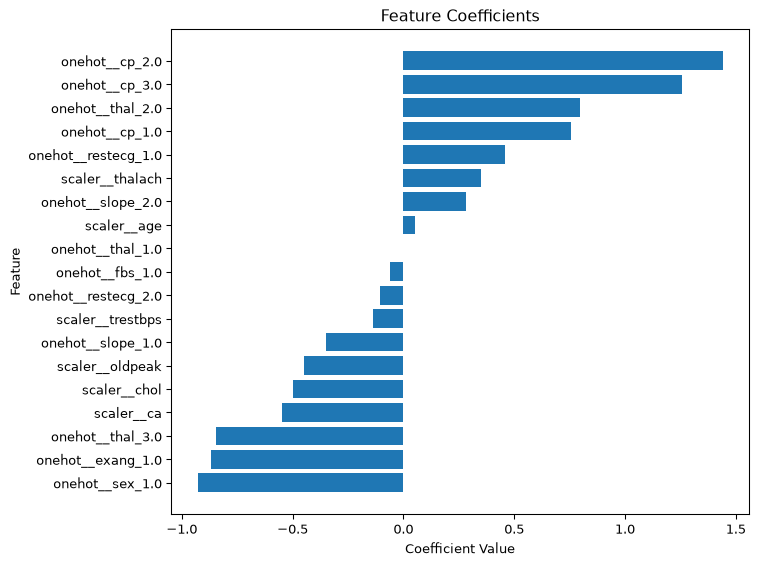

In [10]:
# Visualize the fitted coefficients

coef_plot_df = coef_df.sort_values(by='Coefficient')
plt.figure(figsize=(8, 6))
plt.barh(coef_plot_df['Feature'], coef_plot_df['Coefficient'])
plt.title('Feature Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

With the first category of each encoded attribute used as a reference, a
positive coefficient raises the fitted log-odds of heart-disease
presence relative to that reference, holding the other transformed
features fixed. A negative coefficient lowers those log-odds.

Coefficient magnitude also depends on feature scaling and
regularization. These coefficients describe associations in this fitted
model; they do not establish that a feature causes heart disease.

## Definition

**Ordinal encoding** is a technique that assigns numerical values to
categorical attributes based on their inherent order or rank.

## Feature Engineering - Ordinal

For attributes with values such as **‘Poor’**, **‘Average’**, and
**‘Good’**, an ordinal encoding can preserve their ordering.

. . .

However!

In [11]:
from sklearn.preprocessing import OrdinalEncoder

X =[['Poor'], ['Average'], ['Good'], ['Average'], ['Average']]

encoder = OrdinalEncoder()

encoder.fit(X)
encoder.transform(X)

array([[2.],
       [0.],
       [1.],
       [0.],
       [0.]])

## OrdinalEncoder (revised)

In [12]:
from sklearn.preprocessing import OrdinalEncoder

X =[['Poor'], ['Average'], ['Good'], ['Average'], ['Average']]

encoder = OrdinalEncoder(categories=[['Poor', 'Average', 'Good']])

encoder.fit(X)

X_encoded = encoder.transform(X)

X_encoded

array([[0.],
       [1.],
       [2.],
       [1.],
       [1.]])

The desired order of the categories must be explicitly provided to the
encoder; otherwise, it defaults to alphabetical order.

An ordinal encoder is appropriate when categorical attributes have a
clear, inherent order or ranking, such as ‘Low’, ‘Medium’, and ‘High’,
or ‘Poor’, ‘Average’, and ‘Good’. This encoding method preserves the
ordinal relationships among categories.

When data is inherently ordinal, this encoding is more compact and can
be advantageous for machine learning models. However, if there is any
uncertainty about the ordinal nature of the data, it is safer to use a
`OneHotEncoder`.

## Definition

**Discretization** maps a continuous or fine-grained numerical feature
into a finite set of intervals.

AKA **binning**, **bucketing**, or **quantization**.

## Feature Engineering: Binning

**Example**: Categorizing ages into bins such as ‘infant’, ‘child’,
‘teen’, ‘adult’, and ‘senior citizen’.

. . .

**Possible advantage**:

- Encodes useful domain thresholds and can reduce model complexity.

**Disadvantages**:

- Discards differences within each interval and introduces abrupt
  boundaries.
- Requires defensible cut points; for example, the starting age for
  ‘senior citizen’ could be 60, 65, or 70[1].

Predefined bins can help a decision tree produce a more compact model
because the tree no longer has to discover every threshold from the
available sample.

However, this strong inductive bias can hide useful variation or prevent
the estimator from discovering better boundaries. Binning is therefore a
modelling choice, not an automatic preprocessing step.

Cross-validation is an effective method to determine the best encoding
scheme, but it is essential to withhold the test set until the final
evaluation phase of the project to prevent data leakage and ensure
unbiased assessment.

## FunctionTransformer

[1] Your instructor is concerned with your choice of cutoff

In [13]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import FunctionTransformer

bins = [0, 1, 13, 20, 60, np.inf]
labels = ['infant', 'kid', 'teen', 'adult', 'senior citizen']

transformer = FunctionTransformer(
    pd.cut, kw_args={'bins': bins, 'labels': labels, 'retbins': False}
)

X = np.array([0.5, 2, 15, 25, 97])
transformer.fit_transform(X)

['infant', 'kid', 'teen', 'adult', 'senior citizen']
Categories (5, str): ['infant' < 'kid' < 'teen' < 'adult' < 'senior citizen']

See also: <a
href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.KBinsDiscretizer.html"
class="external" data-icon="true">KBinsDiscretizer</a>

# Scaling

## What is it?

**Scaling attributes** ensures that their values fall within
**comparable ranges**.

## Why?

Why do some estimators require comparable feature scales?

Scaling changes the geometry and numerical conditioning of a learning
problem. Whether it helps depends on the estimator.

Distance-based methods such as k-nearest neighbours and k-means are
sensitive because a large-scale feature can dominate the distance. RBF
kernels and regularized linear models are also scale-sensitive.
Gradient-based optimization often converges more readily when feature
scales are comparable.

Tree-based models make threshold comparisons within one feature at a
time, so monotonic rescaling usually leaves their possible partitions
unchanged.

Scaling does not decide how important a feature *should* be. Domain
knowledge and the model’s intended geometry still matter.

## Scenario

We pretend to predict a house price using **k-Nearest Neighbors (KNN)
regression** with two features:

- $x_1$: number of rooms (small scale)
- $x_2$: square footage (large scale)

## Data (three houses)

In [14]:
import numpy as np
import pandas as pd

# Three examples (rooms, sqft); prices only for b and c (training)
point_names = ["a", "b", "c"]
X = np.array([
    [4, 1500.0],  # a (query)
    [8, 1520.0],  # b (train)
    [4, 1300.0],  # c (train)
], dtype=float)

prices = pd.Series([np.nan, 520_000, 390_000], index=point_names, name="price")

df = pd.DataFrame(X, columns=["rooms", "sqft"], index=point_names)
display(df)
display(prices.to_frame())

**Note.** We’ll treat **b** and **c** as the training set, and **a** as
the query whose price we want to predict.

## Euclidean distances (unscaled)

When one feature has a much larger scale (e.g., square footage), it can
dominate the sum.

In [15]:
from sklearn.metrics import pairwise_distances

dist_unscaled = pd.DataFrame(
    pairwise_distances(df.values, metric="euclidean"),
    index=df.index, columns=df.index
)
dist_unscaled

In [16]:
print("Nearest to 'a' (unscaled):", dist_unscaled.loc["a"].drop("a").idxmin())

Nearest to 'a' (unscaled): b

## Proper scaling for modeling

For a fair ML workflow, compute scaling parameters on the training data
(**b**, **c**) only, then transform both train and query:

In [17]:
from sklearn.preprocessing import StandardScaler

train_idx = ["b", "c"]
query_idx = ["a"]

scaler = StandardScaler()

scaler.fit(df.loc[train_idx])     # fit only on training points

Z = pd.DataFrame(
    scaler.transform(df),
    columns=df.columns, index=df.index
)

Z

## Euclidean distances (after scaling)

In [18]:
dist_scaled = pd.DataFrame(
    pairwise_distances(Z.values, metric="euclidean"),
    index=Z.index, columns=Z.index
)
dist_scaled

In [19]:
print("Nearest to 'a' (scaled):", dist_scaled.loc["a"].drop("a").idxmin())

Nearest to 'a' (scaled): c

## KNN regressor

A 1-NN regressor predicts the price of the nearest training example.
Compare the same estimator with and without scaling.

In [20]:
from sklearn.neighbors import KNeighborsRegressor

X_train = df.loc[train_idx].values
y_train = prices.loc[train_idx].values
X_query = df.loc[query_idx].values

knn_plain = KNeighborsRegressor(n_neighbors=1, metric="euclidean")
knn_plain.fit(X_train, y_train)

knn_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=1, metric="euclidean"))
])

knn_scaled.fit(X_train, y_train)

The pipeline behaves like a single regressor. Its `fit` method learns
the scaler from `X_train` and then fits KNN in the transformed space.
Its `predict` method applies that fitted scaler before searching for
neighbours.

## KNN regressor: results

In [21]:
pred_plain = knn_plain.predict(X_query)[0]
pred_scaled = knn_scaled.predict(X_query)[0]

plain_index = knn_plain.kneighbors(
    X_query, return_distance=False
)[0, 0]
scaled_query = knn_scaled["scaler"].transform(X_query)
scaled_index = knn_scaled["knn"].kneighbors(
    scaled_query, return_distance=False
)[0, 0]

knn_comparison = pd.DataFrame(
    {
        "prediction": [pred_plain, pred_scaled],
        "nearest neighbour": [
            train_idx[plain_index], train_idx[scaled_index]
        ],
    },
    index=["without scaling", "with scaling"],
)

|                     | **Prediction** | **Nearest neighbour** |
|---------------------|---------------:|:----------------------|
| **Without scaling** |      \$520,000 | b                     |
| **With scaling**    |      \$390,000 | c                     |

This deliberately tiny dataset illustrates geometry, not model quality.
Two observations are not enough to estimate stable population means and
standard deviations, and the query has no known price with which to
measure predictive performance. The example demonstrates a change in
neighbour and prediction, not an improvement in accuracy.

## Min-max scaling

Min-max scaling maps each feature to a chosen interval, usually $[0,1]$.

$$
  \frac{x_i^{(j)} - \min^{(j)}}{\max^{(j)} - \min^{(j)}}
$$

The minimum and maximum must be learned from the training data.

**See:** <a
href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html"
class="external" data-icon="true">sklearn.preprocessing.MinMaxScaler</a>

## Standardization

Standardization subtracts the training mean and divides by the training
standard deviation.

$$
\frac{x_i^{(j)} - \mu^{(j)}}{\sigma^{(j)}}
$$

The transformed training feature has mean 0 and variance 1, but its
distribution does **not** become normal and its range is not bounded.

**See:** <a
href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html"
class="external"
data-icon="true">sklearn.preprocessing.StandardScaler</a>

## Choosing a scaling method

- **Standardization** is a common choice for distance-based methods,
  regularized linear models, and gradient-based optimization.
- **Min-max scaling** is useful when a bounded input range is required.
- Both methods are sensitive to outliers: min-max scaling uses extremes,
  while standardization uses the mean and standard deviation.
- For strongly skewed features or outliers, investigate the
  data-generating process and consider a justified transformation,
  clipping rule, or `RobustScaler`.
- If several choices are plausible and consequential, compare them
  within cross-validation.

Scaling and distributional transformation solve different problems. A
logarithm can reduce right skew for strictly positive data, but it must
be meaningful for the feature and fitted into the same leakage-safe
workflow. `RobustScaler` uses the median and interquartile range, which
makes its fitted statistics less sensitive to extreme values.

## Scaling methods compared

| **Feature** | **Standardization** | **Min-max scaling** |
|------------|-------------------------|------------------------------------|
| **Output Range** | Not bounded | Typically \[0, 1\] |
| **Center** | Mean at 0 | Not centered |
| **Outlier sensitivity** | Sensitive through the mean and standard deviation | Sensitive through the minimum and maximum |
| **Typical use** | Comparable variance and zero-centred features | A prescribed bounded range |

## Avoid Data Leakage!

The **correct workflow**:

- Split the examples before learning any preprocessing parameters.
- Fit the scaler on the **training data**.
- Reuse that fitted scaler to transform validation, test, and production
  data.
- During cross-validation, fit preprocessing separately inside each
  training fold—normally by placing it in a `Pipeline`.

Means, standard deviations, minima, maxima, category sets, and
imputation values are all learned information. They must come from the
training data only.

The test set simulates unseen data. Allowing it to influence
preprocessing gives the training procedure information that would not be
available when making a genuinely new prediction. This data leakage can
produce an optimistic estimate of generalization performance.

## Normally distributed sample with outliers

In [22]:
import numpy as np
np.random.seed(7)

# Sample characteristics
sample_size = 1000
mu = 57
sigma = 7

# Generate values
norm_values = sigma * np.random.randn(sample_size) + mu

# Add three outliers
norm_values = np.append(norm_values, [92, 95, 98])

## Original distribution

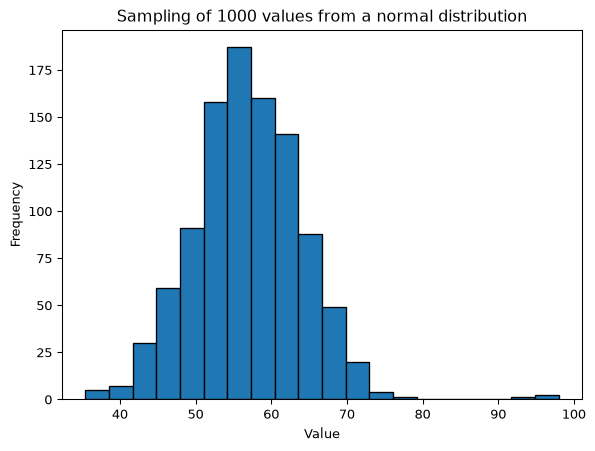

In [23]:
import matplotlib.pyplot as plt

# Plot the histogram
plt.hist(norm_values, bins=20, edgecolor='black')

plt.title(f'Sampling of {sample_size} values from a normal distribution')

plt.xlabel('Value')
plt.ylabel('Frequency')

plt.show()

## Min-max scaling

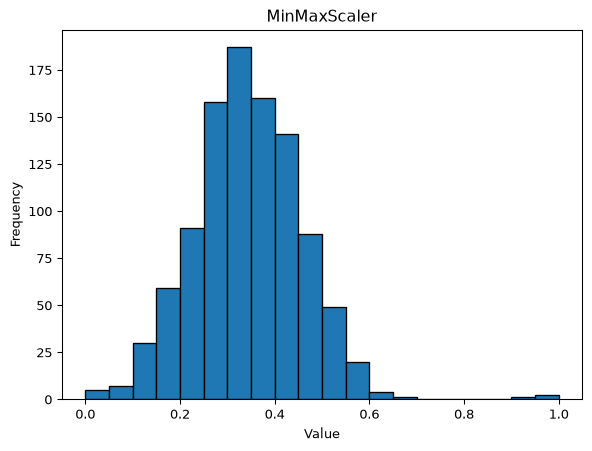

In [24]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

minmax_norm_values = scaler.fit_transform(norm_values.reshape(-1, 1))

# Plot the histogram
plt.hist(minmax_norm_values, bins=20, edgecolor='black')

plt.title(f'MinMaxScaler')

plt.xlabel('Value')
plt.ylabel('Frequency')

plt.show()

Min-max scaling of values from a normal distribution containing high
outliers.

The largest observed value is mapped to 1 and the smallest to 0. The
high outliers stretch that interval, compressing most observations into
its lower portion. Min-max scaling does not imply that the transformed
mean should be 0.5.

## Standardization

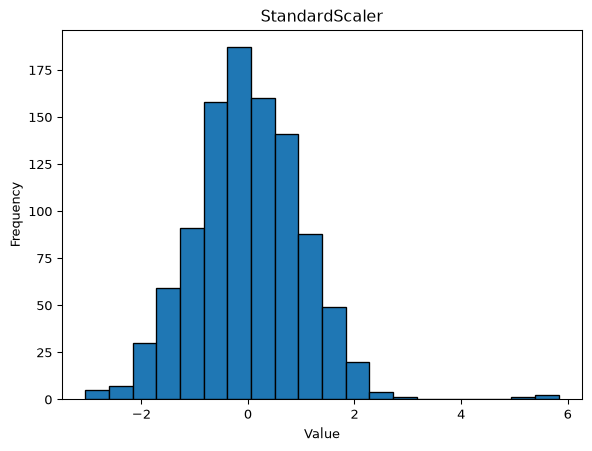

In [25]:
standard_scaler = StandardScaler()

standard_norm_values = standard_scaler.fit_transform(
    norm_values.reshape(-1, 1)
)

# Plot the histogram
plt.hist(standard_norm_values, bins=20, edgecolor='black')

plt.title(f'StandardScaler')

plt.xlabel('Value')
plt.ylabel('Frequency')

plt.show()

Standardization (`StandardScaler`) of values from a normal distribution
containing outliers.

Standardization changes the centre and scale but preserves the
distribution’s shape. The bulk of this approximately normal sample lies
near zero, while the outliers remain outliers. The interval $[-2,2]$ is
a useful empirical description for this sample, not a guarantee of
`StandardScaler`.

# Missing Values

## Definition

**Missing values** refer to the absence of data points or entries in a
dataset where a value is expected.

**Age** is a good example, as some patients may withhold their age due
to privacy concerns.

## Handling Missing Values

- **Drop Examples**
  - Reasonable only when enough data remain and the missing rows are not
    systematically different.
- **Drop Features**
  - Suitable when a feature is not essential and too little reliable
    information remains.
- **Use Algorithms Handling Missing Data**
  - Some estimators model missing values directly; many others do not
    accept them.
- **Data Imputation**
  - Replace missing values using statistics or a model learned from the
    training data.

## Definition

**Data imputation** is the process of replacing missing values in a
dataset with substituted values, typically using statistical or machine
learning methods.

## Data Imputation Strategy

Replace missing numerical values with the training **mean** or
**median** of the feature.

In [26]:
from sklearn.impute import SimpleImputer

X_train_missing = np.array([
    [1.0, 10.0],
    [2.0, np.nan],
    [3.0, 12.0],
])
X_new_missing = np.array([[4.0, np.nan]])

imputer = SimpleImputer(strategy="median")
imputer.fit(X_train_missing)
imputer.transform(X_new_missing)

array([[ 4., 11.]])

. . .

- **Limitation**: Univariate imputation ignores relationships between
  features and reduces the observed variability.

- **Categorical Features**: Use the most frequent category or an
  explicit `"missing"` category when that representation is appropriate.

Missingness can be **completely at random**, related to other observed
features, or related to the missing value itself. These mechanisms are
often described as MCAR, MAR, and MNAR. A simple imputer does not
determine which mechanism produced the missing values.

Mean, median, and most-frequent imputation are useful baselines, but
they can distort distributions and relationships. The imputation
strategy is part of the model and must be assessed on held-out data.

As with scaling, fit the imputer only on the training partition. A
pipeline repeats that fit correctly within every cross-validation fold.

## Preserve Missingness Information

An imputed value can be accompanied by a binary feature indicating that
the original value was missing.

In [27]:
imputer_with_indicator = SimpleImputer(
    strategy="median", add_indicator=True
)
imputer_with_indicator.fit_transform(X_train_missing)

array([[ 1., 10.,  0.],
       [ 2., 11.,  1.],
       [ 3., 12.,  0.]])

`add_indicator=True` lets an estimator use the fact that a value was
missing as a separate signal. This can help when the observation process
is informative—for example, when one measurement is ordered only for
higher-risk patients.

A sentinel value outside the normal range can serve a similar purpose
for some tree-based models, but it can badly distort distances or linear
relationships. An explicit indicator communicates the intent more
clearly.

## Predict a Missing Feature

- Select a feature containing missing values as the prediction target.
- Use rows where that feature is observed as training examples.
- Use the remaining observed features as inputs.
- Predict the missing entries with a regression or classification model.

## Using ML for Imputation

1.  **Neighbour-Based Method**:

    - Use $k$ nearest neighbors (k-NN) to find the $k$ closest examples
      and impute using the non-missing values from the neighborhood.

2.  **Iterative Model-Based Methods**:

    - Predict each incomplete feature from the others and repeat the
      process across features.

<a href="https://scikit-learn.org/stable/modules/impute.html"
class="external" data-icon="true">Consult the scikit-learn imputation
guide</a> or <a
href="https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html"
class="external" data-icon="true"><code>KNNImputer</code>
documentation</a>.

## Why Use these Methods?

- **Possible advantage**:
  - Can use relationships between features that univariate imputation
    ignores.
- **Limitations**:
  - More computation and modelling choices do not guarantee better
    predictions.
  - The imputer must still be fitted inside each training split or
    cross-validation fold.

# Class Imbalance Remedies

## From Evaluation to Intervention

[Lecture 7](../07/slides.html) established that class imbalance can hide
poor performance on an infrequent class and that evaluation must reflect
the decision problem.

This lecture asks a different question:

> How can the **training procedure** respond to class imbalance without
> contaminating evaluation?

Lecture 7 already developed the confusion matrix, accuracy, precision,
recall, $F_1$, micro and macro averaging, threshold trade-offs, ROC
curves, and precision–recall curves. Those definitions and formulas are
not repeated here.

The important transition is from **detecting** a problem during
evaluation to **changing** the training procedure. A remedy is useful
only if it improves the application-relevant validation measure
established in Lecture 7.

## Training-Time Remedies

- **Class or sample weights:** Make errors on selected examples
  contribute more strongly to the training objective.
- **Random oversampling:** Repeat minority-class training examples.
- **Random undersampling:** Retain fewer majority-class training
  examples.
- **SMOTE:** Interpolate synthetic minority-class examples from
  neighbouring training examples.
- **Decision threshold:** Select an operating point using validation
  data, as introduced in Lecture 7.

Implementations: <a
href="https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html"
class="external" data-icon="true"><code>class_weight</code></a> and
<a href="https://imbalanced-learn.org/stable/index.html"
class="external" data-icon="true"><code>imbalanced-learn</code></a>.

Class weights change the contribution of training examples without
creating or deleting observations. Oversampling can overfit repeated
examples, whereas undersampling can discard useful majority-class
variation.

SMOTE constructs synthetic points between minority-class neighbours
(Chawla et al. 2002). This interpolation can be inappropriate when a
straight line between two observations leaves the set of plausible
examples. Ordinary SMOTE also assumes numerical features; mixed
numerical and categorical data require an appropriate variant such as
`SMOTENC`.

No remedy is universally best. Compare plausible choices using the
validation procedure and application-relevant measures established in
Lecture 7.

## Keep Evaluation Untouched

- Preserve the natural class distribution in validation and test data.
- Apply resampling **only to a training partition**.
- During cross-validation, resample separately inside each training
  fold.
- Place resampling and the estimator in an `imbalanced-learn` pipeline.
- Reserve the test set for the final evaluation after selecting the
  remedy and any decision threshold.

Resampling before the train/test split leaks information and also
creates an unrealistic evaluation distribution. Resampling once before
cross-validation has the same problem because a synthetic or repeated
example can influence both training and validation folds.

An `imbalanced-learn` pipeline calls the sampler only while fitting each
training fold. Its prediction path does not resample validation, test,
or production examples.

# New Features

## Definition

**Feature engineering** is the process of **creating**,
**transforming**, and **selecting** variables (attributes) from raw data
to improve the performance of machine learning models.

Here, our focus is on **creating** new attributes from raw data.

## Exploration

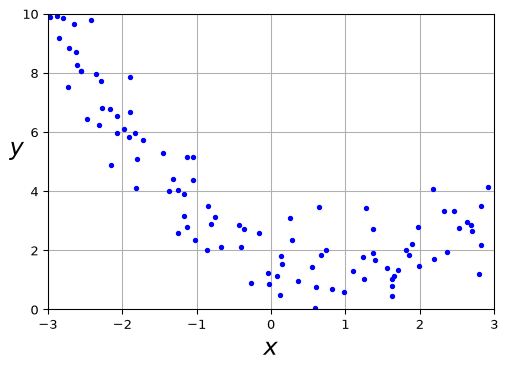

In [28]:
import numpy as np

np.random.seed(42)

X = 6 * np.random.rand(100, 1) - 3
y = 0.5 * X ** 2 - X + 2 + np.random.randn(100, 1)

import matplotlib as mpl
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.plot(X, y, "b.")
plt.xlabel("$x$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([-3, 3, 0, 10])
plt.grid(True)
plt.show()

**Attribution**: Géron (2022), Chapter 4

The scatter plot has a curved trend: the response decreases and then
increases as $x$ changes. A model that uses only an intercept and the
original feature $x$ cannot represent that curvature.

The fixed random seed makes the generated sample reproducible.
Reproducibility is useful for comparing models and debugging, but a
single seed does not establish that a result is stable across possible
samples.

## Linear Regression

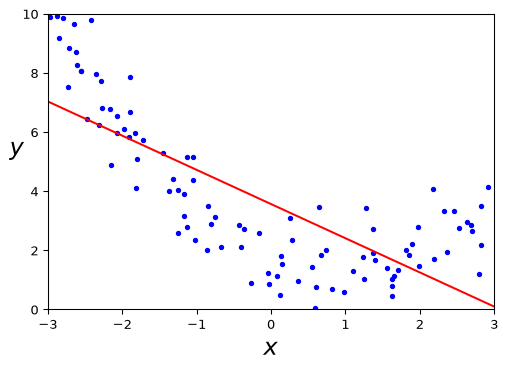

In [29]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)

X_new = np.array([[-3], [3]])
y_pred = lin_reg.predict(X_new)

plt.figure(figsize=(6,4))

plt.plot(X, y, "b.")
plt.plot(X_new, y_pred, "r-")
plt.xlabel("$x$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([-3, 3, 0, 10])
plt.show()

A **linear model** inadequately represents this dataset.

The best-fitting straight line balances residuals across the dataset,
but changing its slope and intercept cannot create a turning point. The
model is underfitting because its representation is too restrictive for
the observed relationship.

## `PolynomialFeatures`

In [30]:
from sklearn.preprocessing import PolynomialFeatures

poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_features.fit_transform(X)

. . .

In [31]:
X[0]

array([-0.75275929])

. . .

In [32]:
X_poly[0]

array([-0.75275929,  0.56664654])

. . .

>  **<a
> href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html"
> class="external"
> data-icon="true">sklearn.preprocessing.PolynomialFeatures</a>**
>
> Generate a new feature matrix consisting of all polynomial
> combinations of the features with degree less than or equal to the
> specified degree. For example, if an input sample is two dimensional
> and of the form $[a, b]$, the degree-2 polynomial features are
> $[1, a, b, a^2, ab, b^2]$.

## `PolynomialFeatures`

Given two features $a$ and $b$, `PolynomialFeatures` with `degree=3`
would add $a^2$, $a^3$, $b^2$, $b^3$, as well as, $ab$, $a^2b$, $ab^2$!

. . .

> **Warning**
>
> With `include_bias=True`, the total number of output features is
>
> $$
> \binom{D+d}{d} = \frac{(D+d)!}{d!D!},
> $$
>
> where $D$ is the number of input features. With `include_bias=False`,
> subtract one.

The output count includes the original features as well as powers and
interactions. It grows quickly with both $D$ and $d$, which increases
computation and the risk of overfitting. Select the degree with
validation and use regularization when appropriate.

## Polynomial Regression

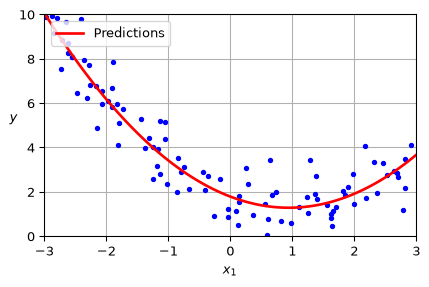

In [33]:
lin_reg = LinearRegression()
lin_reg = lin_reg.fit(X_poly, y)

X_new = np.linspace(-3, 3, 100).reshape(100, 1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize=(5, 3))
plt.plot(X, y, "b.")
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

`LinearRegression` fitted to features $[x, x^2]$.

## Learned Polynomial

The data was generated according to the following equation, with the
inclusion of Gaussian noise.

$$
  y = 0.5 x^2 - 1.0 x + 2.0
$$

Presented below is the learned model.

$$
  \hat{y} = 0.56 x^2 + (-1.06) x + 1.78
$$

In [34]:
lin_reg.coef_, lin_reg.intercept_

(array([[-1.06633107,  0.56456263]]), array([1.78134581]))

Linearity refers to the fitted coefficients, not necessarily to the
original input. After defining $z_1=x$ and $z_2=x^2$, linear regression
fits

$$
\hat{y}=\theta_0+\theta_1z_1+\theta_2z_2.
$$

This expression is linear in $\theta_0,\theta_1,\theta_2$, even though
it traces a curve as $x$ changes. `PolynomialFeatures` changes the
feature representation; it does not change the fitting algorithm into a
different kind of regression estimator.

The fitted coefficients are close to the generating coefficients because
the model contains the relevant quadratic term and the sample contains
moderate Gaussian noise. Exact recovery is neither expected nor
required.

# Data Quantity and Augmentation

## Size does matter

For the language task studied by Banko and Brill, increasing the
training corpus produced large gains across several learning algorithms.

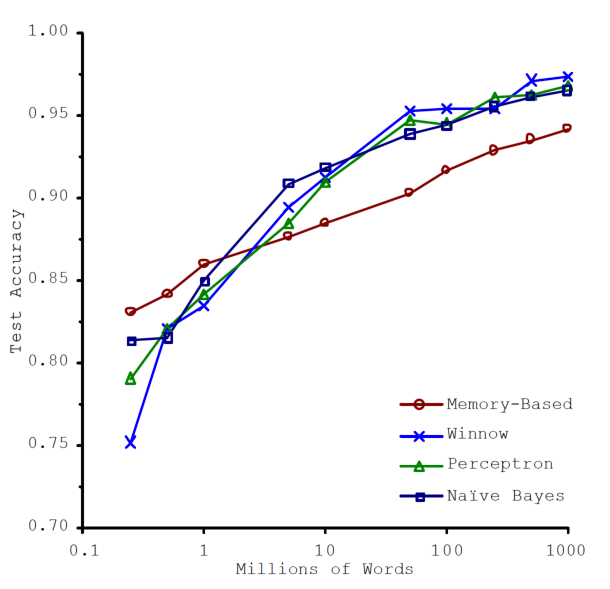

**Attribution**: Banko and Brill (2001)

The result in Banko and Brill (2001) concerns one natural-language
disambiguation task and should not be read as a universal law that more
examples always solve a learning problem.

Additional data help when they provide relevant, correctly labelled, and
representative information. More examples do not repair a mismatched
target, systematic label errors, omitted subpopulations, or a
distribution shift between training and deployment.

For some large neural models, empirical scaling laws relate loss to
training data, parameter count, and computation over a studied range
(Kaplan et al. 2020). Those regularities do not remove the need to
examine data quality and coverage.

## Definition

**Data augmentation** creates additional training examples with
transformations that should preserve the target label.

**Purpose**: Encode plausible invariances and improve robustness to
variation expected in deployment.

## Data Augmentation

- **Images**: Rotations, translations, crops, flips, or noise—when these
  transformations preserve the label.
  - <a href="https://youtube.com/shorts/DA_-6296G5o" class="external"
    data-icon="true">How to find ancient geoglyphs using machine
    learning?</a>, Sakai et al. (2024)
- **Text**: Carefully controlled paraphrasing or edits that preserve
  meaning and the assigned label.

Generative models can also produce synthetic examples, but
realistic-looking output does not guarantee correct labels,
representative coverage, or independence from the source data.

An augmentation is valid only when its transformation preserves the
target for the application. A horizontal flip may be harmless for many
object categories but invalid for text, medical laterality, or traffic
signs. Synonym replacement can also change nuance or grammar.

Apply augmentation only to training examples and, during
cross-validation, only within the training fold. Validation and test
sets should represent naturally occurring inputs.

Synthetic data require the same scrutiny as collected data.
Indiscriminate reuse of model-generated content can narrow the
represented distribution or amplify artifacts; Shumailov et al. (2024)
discusses one form of this risk.

# Conclusion

## Further readings

![](https://m.media-amazon.com/images/I/51XUfJm64KL._AC_UF350,350_QL50_.jpg)

- <a href="http://www.mlebook.com/wiki/doku.php" class="external"
  data-icon="true"><strong>Machine Learning Engineering</strong></a> by
  <a href="https://www.linkedin.com/in/andriyburkov" class="external"
  data-icon="true">Andriy Burkov</a> (Burkov 2020).
- Covers data collection, storage, preprocessing, feature engineering,
  model testing and debugging, deployment, retirement, and maintenance.
- From the author of <a href="https://themlbook.com" class="external"
  data-icon="true"><strong>The Hundred-Page Machine Learning
  Book</strong></a> (Burkov 2019).
- Available under a “read first, buy later” model.

## Summary

- Match **categorical encodings** to nominal or ordinal meaning.
- Fit **scaling**, **encoding**, and **imputation** on training data
  through a pipeline.
- Choose scaling according to the estimator; scaling does not make a
  feature normally distributed.
- Apply **class-imbalance remedies** only within training partitions and
  evaluate on the natural distribution.
- Use polynomial and interaction features to expand a model’s
  representation while controlling complexity.
- Value representative, correctly labelled data and use only
  label-preserving augmentation.

## Next lecture

- **Next:** artificial neural networks.

## References

Banko, Michele, and Eric Brill. 2001. “Scaling to Very Very Large
Corpora for Natural Language Disambiguation.” *Proceedings of the 39th
Annual Meeting on Association for Computational Linguistics* (USA), ACL
’01, 26–33. <https://doi.org/10.3115/1073012.1073017>.

Burkov, A. 2020. *Machine Learning Engineering*. True Positive
Incorporated. <https://books.google.ca/books?id=HeXizQEACAAJ>.

Burkov, Andriy. 2019. *The Hundred-Page Machine Learning Book*. Andriy
Burkov.

Chawla, N V, K W Bowyer, L O Hall, and W P Kegelmeyer. 2002.
“<span class="nocase">SMOTE: Synthetic minority over-sampling
technique</span>.” *Journal of Artificial Intelligence Research* 16:
321–57.

Géron, Aurélien. 2022. *Hands-on Machine Learning with Scikit-Learn,
Keras, and TensorFlow*. 3rd ed. O’Reilly Media, Inc.

Halevy, Alon, Peter Norvig, and Fernando Pereira. 2009.
“<span class="nocase">The Unreasonable Effectiveness of Data</span>.”
*IEEE Intelligent Systems* 24 (2): 8–12.

Kaplan, Jared, Sam McCandlish, Tom Henighan, et al. 2020. *Scaling Laws
for Neural Language Models*. <https://arxiv.org/abs/2001.08361>.

Sakai, Masato, Akihisa Sakurai, Siyuan Lu, et al. 2024.
“<span class="nocase">AI-accelerated Nazca survey nearly doubles the
number of known figurative geoglyphs and sheds light on their
purpose</span>.” *Proceedings of the National Academy of Sciences* 121
(40): e2407652121. <https://doi.org/10.1073/pnas.2407652121>.

Shumailov, Ilia, Zakhar Shumaylov, Yiren Zhao, Nicolas Papernot, Ross
Anderson, and Yarin Gal. 2024. “<span class="nocase">AI models collapse
when trained on recursively generated data</span>.” *Nature* 631 (8022):
755–59. <https://doi.org/10.1038/s41586-024-07566-y>.

# Appendix: Video

## Unreasonable Effectiveness of Data

<https://youtu.be/yvDCzhbjYWs>

Supplementary presentation related to Halevy et al. (2009) and later
empirical scaling work such as Kaplan et al. (2020).

Peter Norvig’s presentation runs for just over one hour and is provided
for independent study rather than classroom viewing. The associated 2009
paper predates the modern wave of large deep-learning systems but
remains useful for examining the relationship between data scale and
modelling choices.

# Appendix: Pipeline

## Pipeline

In [35]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="median", add_indicator=True)),
    ('scaler', StandardScaler()),
])

preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        make_column_selector(dtype_include=np.number),
    ),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        make_column_selector(dtype_exclude=np.number),
    ),
])

full_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression()),
])

This template keeps every learned preprocessing step with the estimator.
Numerical columns are imputed and standardized; categorical columns are
one-hot encoded. The selectors choose columns by data type, so the
template does not depend on lecture-specific column names.

Calling `full_pipeline.fit(X_train, y_train)` fits every component on
the same training examples. The fitted pipeline can then transform and
classify validation, test, or production examples consistently.

------------------------------------------------------------------------

Marcel **Turcotte**

<Marcel.Turcotte@uOttawa.ca>

School of Electrical Engineering and **Computer Science** (EE**CS**)

University of Ottawa